# 04_calendar ? Calendar Availability & Temporal Analysis (TV4 ? Vu Pham Khanh Nam)
- **Cohort:** `DSE2049-C01-G10-toronto` (4 snapshots: `2025-09-11`, `2025-12-12`, `2026-03-19`, `2026-06-15`, `window_days = 90`).
- **Contract (`docs/CONTRACTS.md`):** Dedupe by `(snapshot_date, listing_id, date)` before aggregation; never use `calendar.price`; distinguish `availability_rate` from `occupancy`.

In [3]:
from collections import Counter, defaultdict
from pathlib import Path
import sys

root = Path.cwd() if (Path.cwd() / 'configs').exists() else Path.cwd().parent
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))

from airbnb.io import load_config, rows
from airbnb.loading import read_assignment, snapshot_rows
from airbnb import calendar, viz_calendar

raw_cfg = load_config(root / 'configs/toronto.yaml')
cfg = raw_cfg[0] if isinstance(raw_cfg, tuple) else raw_cfg
assigned = read_assignment(cfg, root, demo=False)
snapshots = cfg['snapshots']
window_days = cfg['calendar']['window_days']

area_counts = Counter(assigned.areas.values())
print(f'Data code: {assigned.code} | Tong so listing_id duoc giao: {len(assigned.listing_ids)}')
print('Phan bo 8 analysis_area trong cohort:')
for area, cnt in sorted(area_counts.items()):
    print(f'  - {area}: {cnt} listings')

Data code: DSE2049-C01-G10-toronto | Tong so listing_id duoc giao: 1000
Phan bo 8 analysis_area trong cohort:
  - A01: 130 listings
  - A02: 130 listings
  - A03: 126 listings
  - A04: 121 listings
  - A05: 120 listings
  - A06: 121 listings
  - A07: 130 listings
  - A08: 122 listings


In [4]:
# Chay aggregate() va weekday_weekend_breakdown() tren ca 4 snapshot that
all_cal = []
all_wd_we = []
issues_by_snap = {}

for snap in snapshots:
    cal_iter = snapshot_rows(root, cfg, snap, 'calendar.csv.gz', assignment=assigned, demo=False)
    summary, issues = calendar.aggregate(cal_iter, snap, window_days, assigned.listing_ids)
    all_cal.extend(summary)
    issues_by_snap[snap] = issues

    cal_iter_2 = snapshot_rows(root, cfg, snap, 'calendar.csv.gz', assignment=assigned, demo=False)
    wd_we = calendar.weekday_weekend_breakdown(cal_iter_2, snap, window_days, assigned.listing_ids)
    all_wd_we.extend(wd_we)

    avail_sum = sum(r['available_days'] for r in summary)
    obs_sum = sum(r['observed_days'] for r in summary)
    overall_rate = (avail_sum / obs_sum * 100) if obs_sum else 0.0
    wd_avg = (sum(r['weekday_availability_rate'] for r in wd_we) / len(wd_we) * 100) if wd_we else 0.0
    we_avg = (sum(r['weekend_availability_rate'] for r in wd_we) / len(wd_we) * 100) if wd_we else 0.0
    print(f'[{snap}] listings_co_du_lieu={len(summary)} | avail_rate={overall_rate:.2f}% | '
          f'Weekday(T2-T5)={wd_avg:.2f}% | Weekend(T6-CN)={we_avg:.2f}% | issues={issues}')

[2025-09-11] listings_co_du_lieu=1000 | avail_rate=58.62% | Weekday(T2-T5)=59.62% | Weekend(T6-CN)=57.28% | issues={}
[2025-12-12] listings_co_du_lieu=1000 | avail_rate=66.53% | Weekday(T2-T5)=67.12% | Weekend(T6-CN)=65.71% | issues={}
[2026-03-19] listings_co_du_lieu=1000 | avail_rate=59.89% | Weekday(T2-T5)=60.88% | Weekend(T6-CN)=58.59% | issues={}
[2026-06-15] listings_co_du_lieu=1000 | avail_rate=51.59% | Weekday(T2-T5)=52.40% | Weekend(T6-CN)=50.58% | issues={}


In [5]:
# Nap thong tin analysis_area (va price o moc cuoi neu co) de tinh Calendar KPI
def _parse_price(raw):
    if raw is None:
        return None
    s = str(raw).replace('$', '').replace(',', '').strip()
    if not s:
        return None
    try:
        v = float(s)
        return v if 0 < v <= cfg['qa']['price_max'] else None
    except ValueError:
        return None

all_listings = []
latest_snap = snapshots[-1]
personal_csv = root / 'data/listings_real_personal.csv'
personal_prices = {}
if personal_csv.exists():
    for r in rows(personal_csv):
        lid = str(r.get('id') or r.get('listing_id') or '').strip()
        snap_col = str(r.get('snapshot_date') or latest_snap).strip()
        if lid in assigned.listing_ids and snap_col == latest_snap:
            p = _parse_price(r.get('price'))
            if p is not None:
                personal_prices[lid] = p

for snap in snapshots:
    raw_listings = root / cfg['paths']['raw'] / snap / 'listings.csv.gz'
    if raw_listings.exists():
        for r in snapshot_rows(root, cfg, snap, 'listings.csv.gz', assignment=assigned, demo=False):
            all_listings.append({
                'snapshot_date': snap,
                'listing_id': str(r['id']).strip(),
                'analysis_area': r['analysis_area'],
                'price': _parse_price(r.get('price')),
            })
    else:
        for lid, area in assigned.areas.items():
            all_listings.append({
                'snapshot_date': snap,
                'listing_id': lid,
                'analysis_area': area,
                'price': personal_prices.get(lid) if snap == latest_snap else None,
            })

all_kpi = calendar.metrics(all_cal, all_listings, cfg)

# In bang so sanh Availability Rate (%) theo 8 analysis_area qua 4 snapshot
pivot = defaultdict(dict)
n_latest = {}
for r in all_kpi:
    pivot[r['analysis_area']][r['snapshot_date']] = r['availability_rate'] * 100.0
    if r['snapshot_date'] == latest_snap:
        n_latest[r['analysis_area']] = r['listing_n']

header = f"{'Analysis Area':<28} | " + ' | '.join(f'{s:>10}' for s in snapshots) + ' | Delta(Q4-Q1) | n_latest'
print(header)
print('-' * len(header))
for area in sorted(pivot.keys()):
    vals = [pivot[area].get(s, float('nan')) for s in snapshots]
    delta = vals[-1] - vals[0]
    row_str = f"{area:<28} | " + ' | '.join(f'{v:9.2f}%' for v in vals) + f' | {delta:+10.2f}% | {n_latest.get(area, 0):>8}'
    print(row_str)

Analysis Area                | 2025-09-11 | 2025-12-12 | 2026-03-19 | 2026-06-15 | Delta(Q4-Q1) | n_latest
----------------------------------------------------------------------------------------------------------
A01                          |     62.67% |     70.42% |     61.72% |     47.73% |     -14.94% |      130
A02                          |     52.39% |     60.97% |     53.64% |     45.85% |      -6.55% |      130
A03                          |     63.70% |     70.64% |     63.00% |     55.30% |      -8.40% |      126
A04                          |     60.39% |     69.11% |     61.26% |     52.54% |      -7.85% |      121
A05                          |     61.09% |     65.30% |     56.71% |     57.15% |      -3.93% |      120
A06                          |     51.97% |     61.56% |     53.84% |     50.25% |      -1.72% |      121
A07                          |     53.92% |     62.02% |     61.58% |     50.06% |      -3.86% |      130
A08                          |     63.13% | 

Da xuat cac bieu do:
 - d:\Tài liệu , bài tập kì 1 năm 2\tài liệu nhóm 10 ltxldl\figures\tv4_availability_timeline_by_area.png


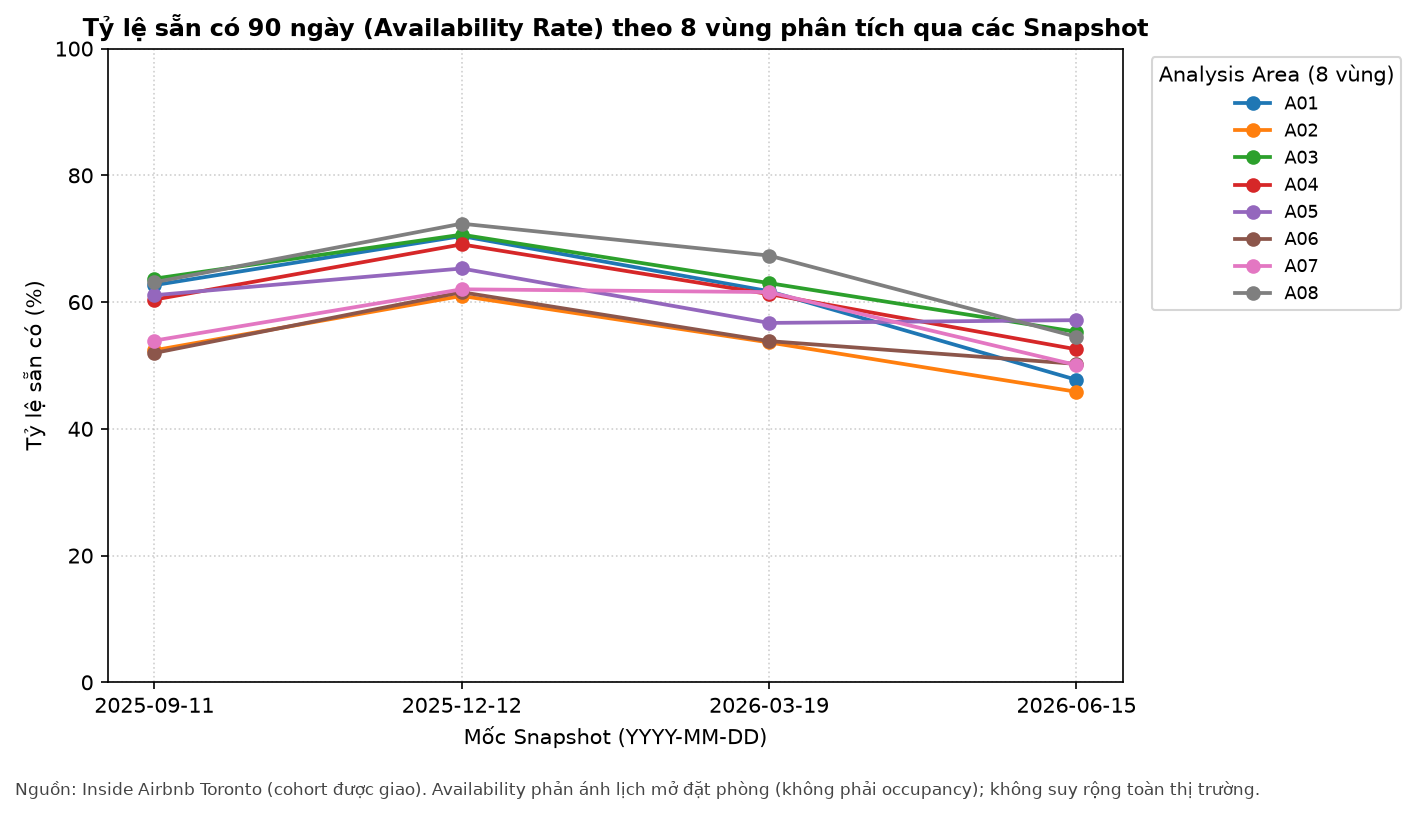

 - d:\Tài liệu , bài tập kì 1 năm 2\tài liệu nhóm 10 ltxldl\figures\tv4_availability_by_analysis_area.png


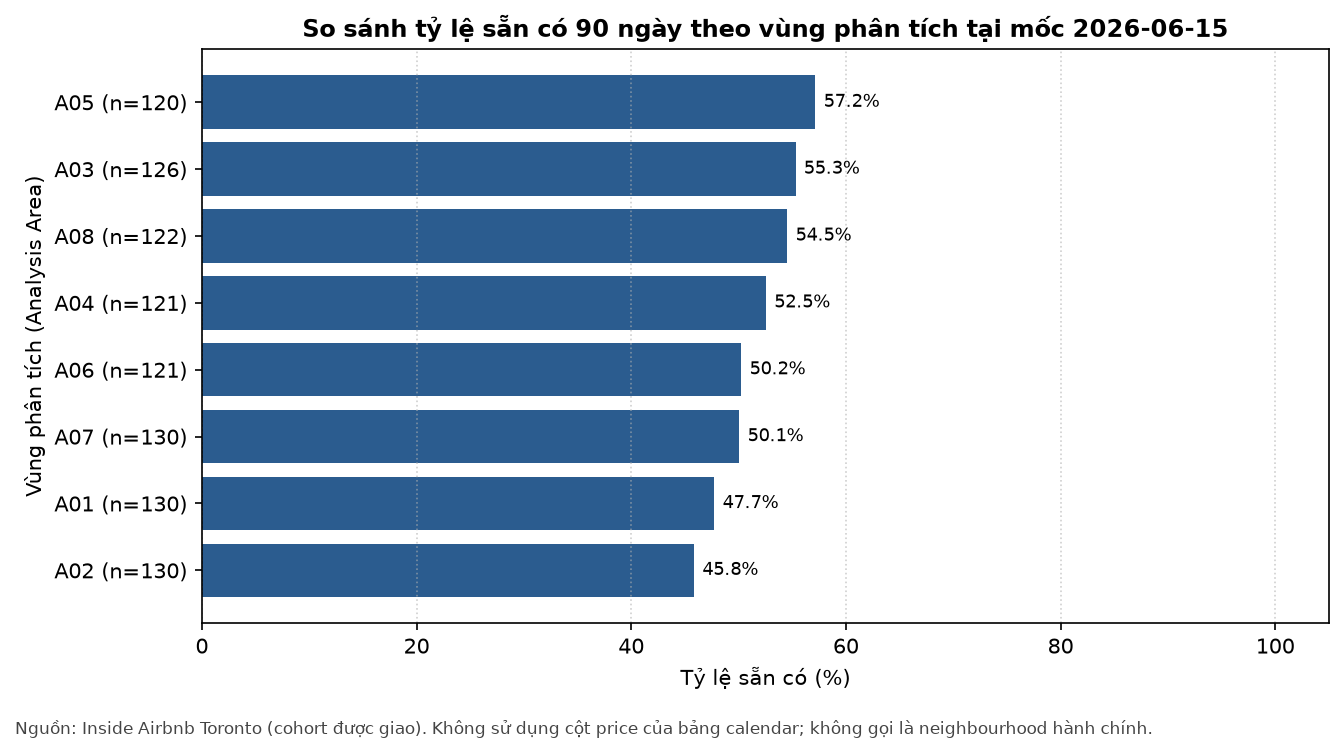

 - d:\Tài liệu , bài tập kì 1 năm 2\tài liệu nhóm 10 ltxldl\figures\tv4_price_vs_availability_latest.png


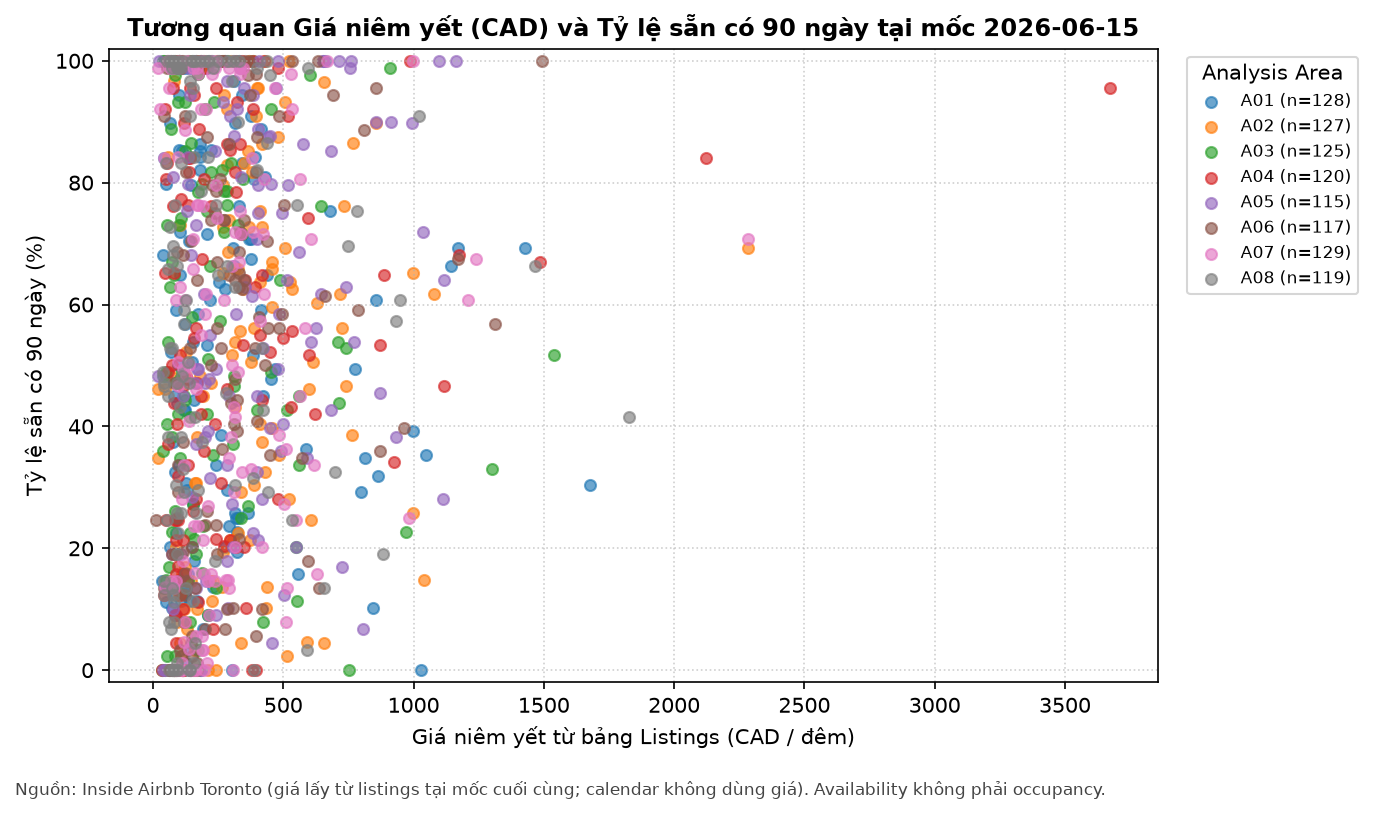

 - d:\Tài liệu , bài tập kì 1 năm 2\tài liệu nhóm 10 ltxldl\figures\tv4_weekday_vs_weekend_by_area.png


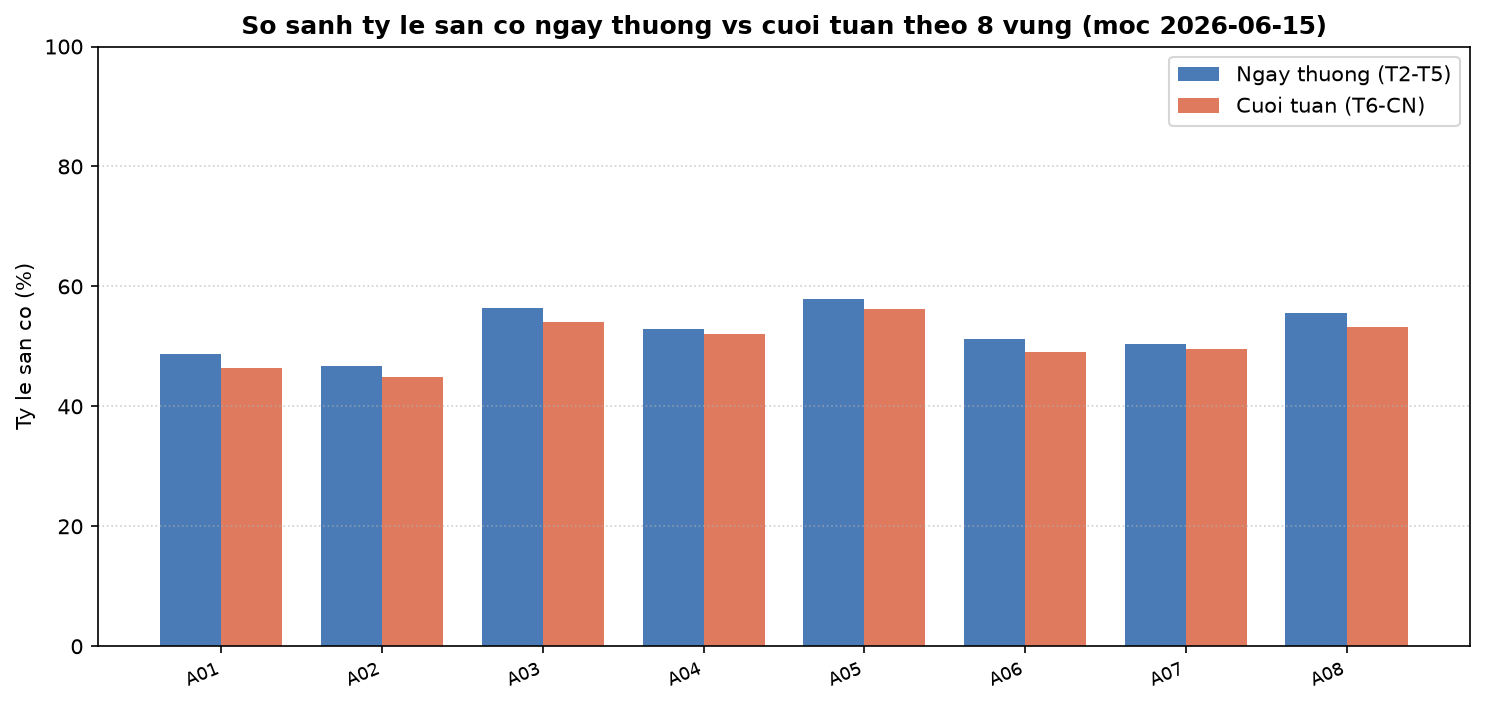

In [6]:
# Xuat 3 bieu do chuan cua viz_calendar.render() + bieu do bo tro Weekday vs Weekend
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

fig_dir = root / cfg['paths']['figures']
tables = {'calendar': all_cal, 'calendar_kpi': all_kpi, 'listings': all_listings}
saved_figs = viz_calendar.render(tables, fig_dir, cfg)

wd_we_latest = [r for r in all_wd_we if r['snapshot_date'] == latest_snap]
by_area_wd = defaultdict(list)
by_area_we = defaultdict(list)
for r in wd_we_latest:
    area = assigned.areas.get(r['listing_id'], 'Unknown')
    by_area_wd[area].append(r['weekday_availability_rate'] * 100.0)
    by_area_we[area].append(r['weekend_availability_rate'] * 100.0)

areas_sorted = sorted(by_area_wd.keys())
wd_means = [sum(by_area_wd[a]) / len(by_area_wd[a]) for a in areas_sorted]
we_means = [sum(by_area_we[a]) / len(by_area_we[a]) for a in areas_sorted]

x = list(range(len(areas_sorted)))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=150)
ax.bar([i - w/2 for i in x], wd_means, width=w, label='Ngay thuong (T2-T5)', color='#4a7bb7')
ax.bar([i + w/2 for i in x], we_means, width=w, label='Cuoi tuan (T6-CN)', color='#e07a5f')
ax.set_xticks(x)
ax.set_xticklabels(areas_sorted, rotation=22, ha='right', fontsize=8.5)
ax.set_ylim(0, 100)
ax.set_ylabel('Ty le san co (%)')
ax.set_title(f'So sanh ty le san co ngay thuong vs cuoi tuan theo 8 vung (moc {latest_snap})', fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
p4 = fig_dir / 'tv4_weekday_vs_weekend_by_area.png'
fig.savefig(p4, bbox_inches='tight')
plt.close(fig)
saved_figs.append(p4)

print('Da xuat cac bieu do:')
for p in saved_figs:
    print(' -', p)
    display(Image(filename=str(p)))